In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import OneHotEncoder
from keras.models import Sequential
from keras.layers import Dense,LSTM,Dropout

In [ ]:
paths=[]
labels=[]
for dirname, _, filenames in os.walk('/content/drive/MyDrive/TESS Toronto emotional speech set data'):
    for filename in filenames:
        paths.append(os.path.join(dirname, filename))
        label = filename[::-1].split('_')[0][::-1]
        labels.append(label.lower())

data = pd.DataFrame({'speech':paths,'label':labels})
data.sample(5)

,speech,label
154,/content/drive/MyDrive/TESS Toronto emotional ...,sad.wav
204,/content/drive/MyDrive/TESS Toronto emotional ...,fear.wav
571,/content/drive/MyDrive/TESS Toronto emotional ...,ps.wav
363,/content/drive/MyDrive/TESS Toronto emotional ...,fear.wav
1313,/content/drive/MyDrive/TESS Toronto emotional ...,happy.wav


In [ ]:
data['label'].value_counts()

sad.wav            400
ps.wav             400
disgust.wav        400
neutral.wav        400
happy.wav          400
angry.wav          400
fear.wav           349
neutral (1).wav      1
Name: label, dtype: int64

In [ ]:
def waveplot(data,sr,emotion):
    plt.figure(figsize=(10,4))
    plt.title(emotion,size=20)
    librosa.display.waveshow(data,sr=sr)
    plt.show()

def spectogram(data,sr,emotion):
    x=librosa.stft(data)
    xdb=librosa.amplitude_to_db(abs(x))
    plt.figure(figsize=(11,4))
    librosa.display.specshow(xdb,sr=sr,x_axis='time',y_axis='hz')
    plt.colorbar()

def ana_emotion(emotion:str, df:pd.DataFrame):
    path=np.array(df['speech'][df['label']==emotion])[0]
    data,sampling_rate=librosa.load(path)
    waveplot(data,sampling_rate,emotion)
    spectogram(data,sampling_rate,emotion)
    display(Audio(path))

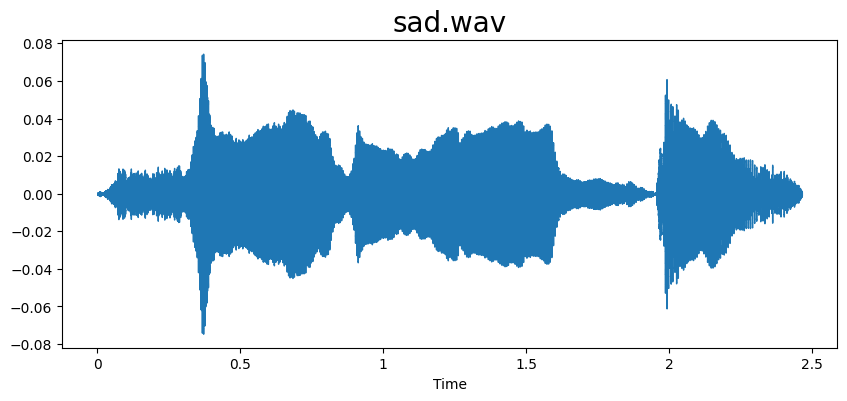

None

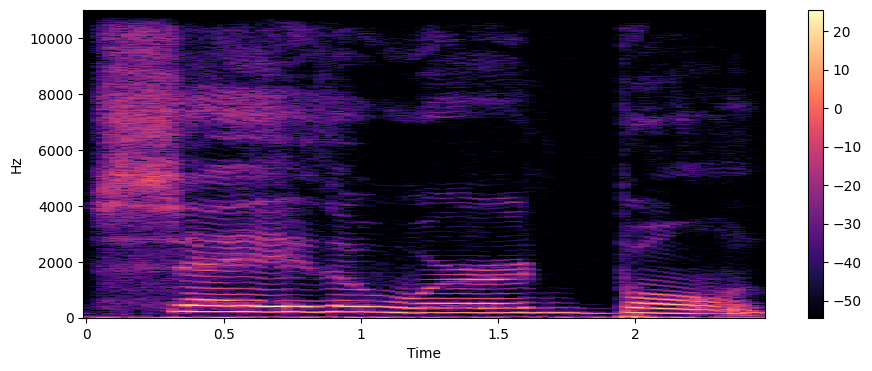

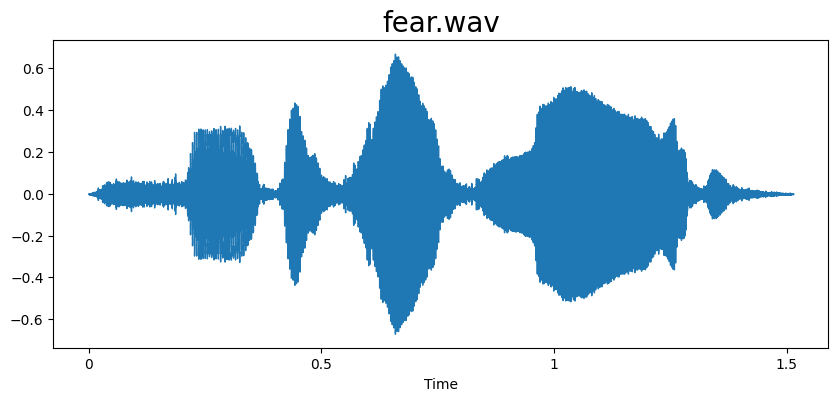

None

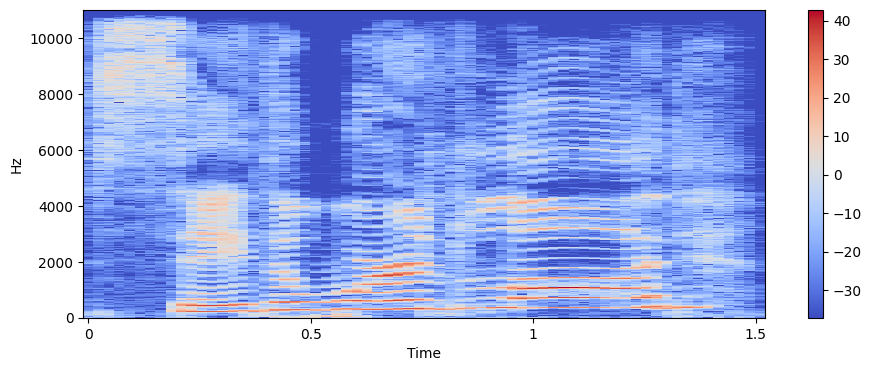

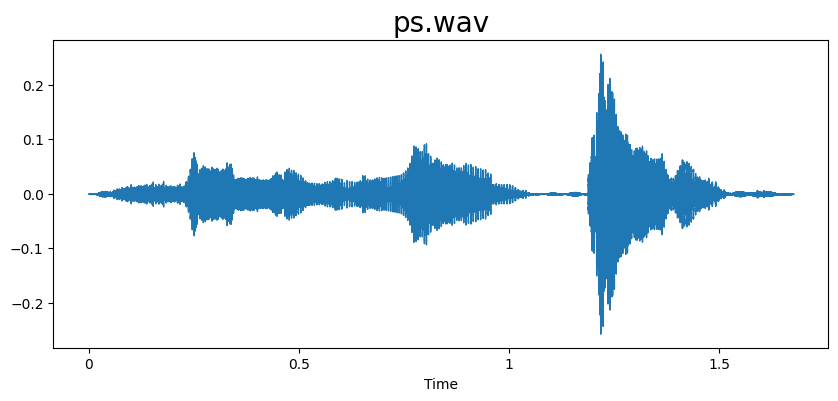

None

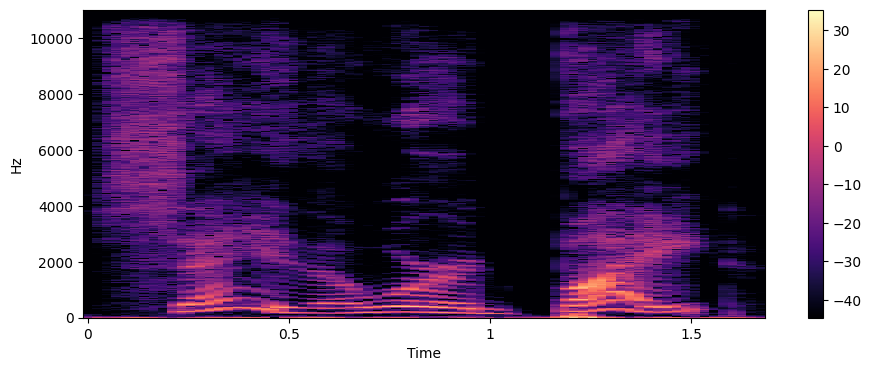

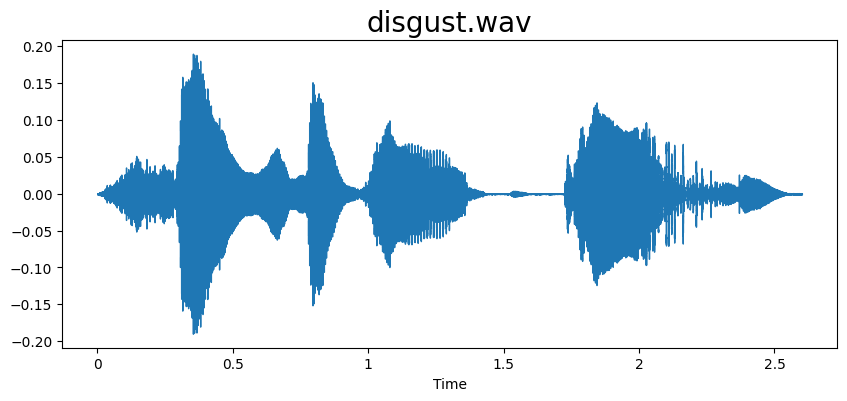

None

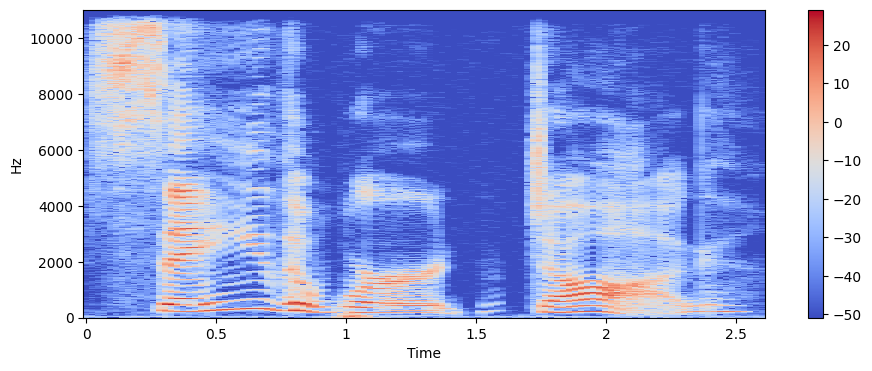

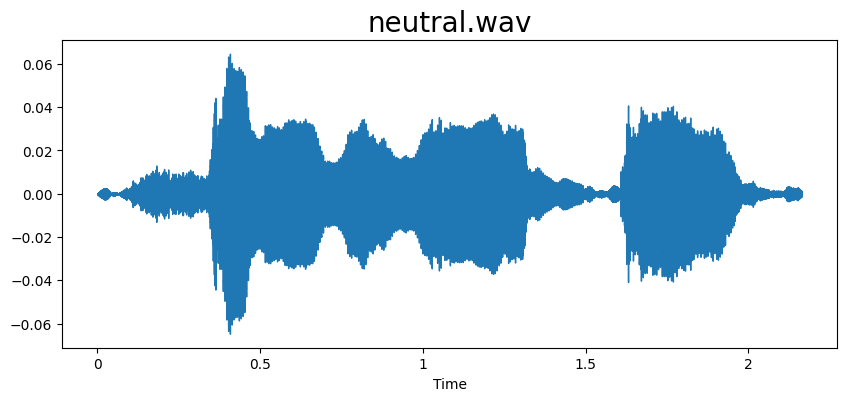

None

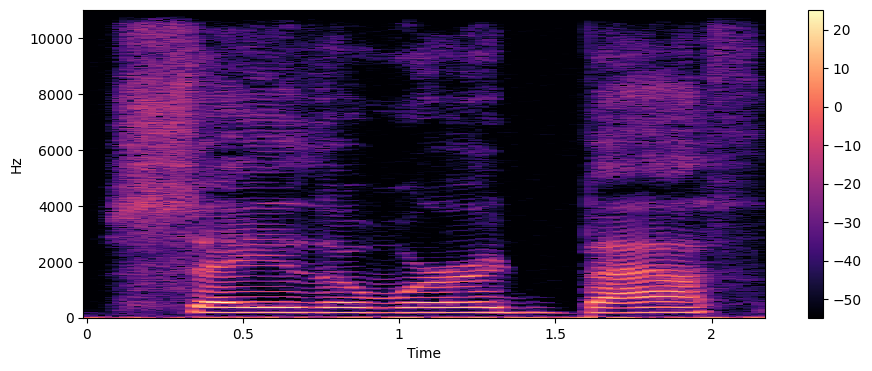

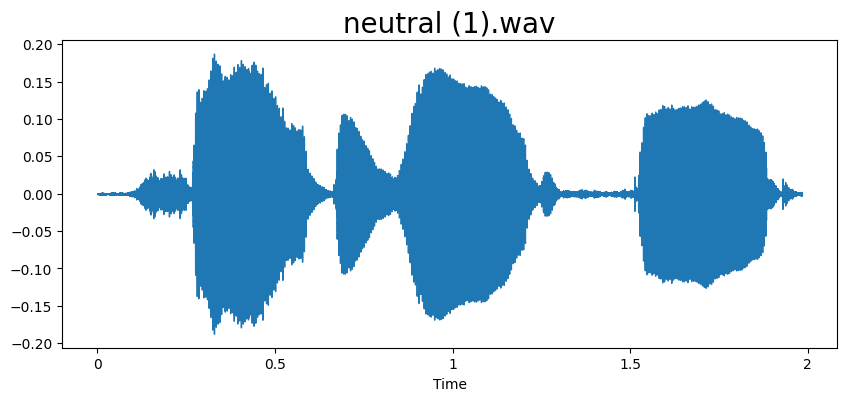

None

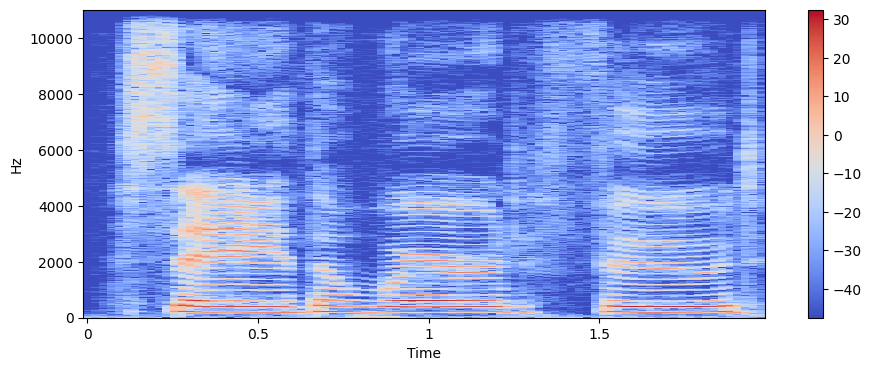

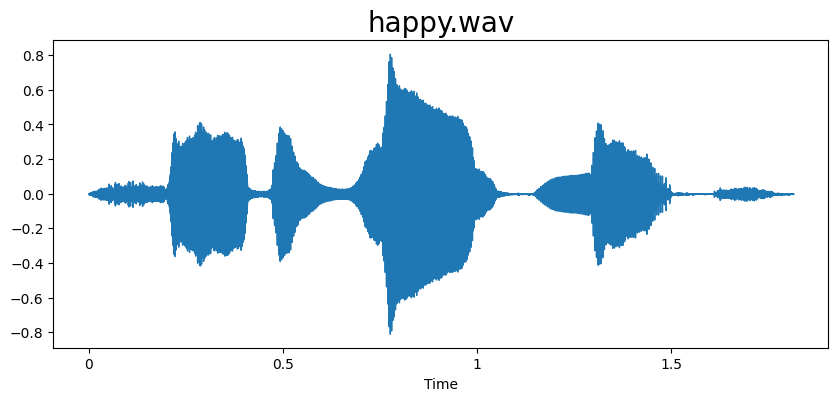

None

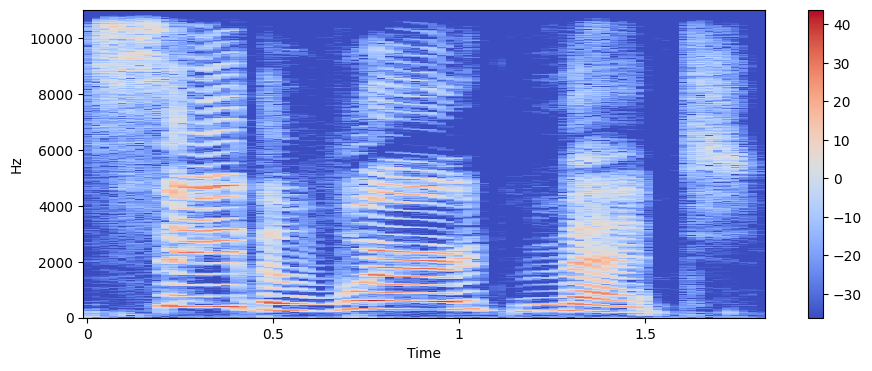

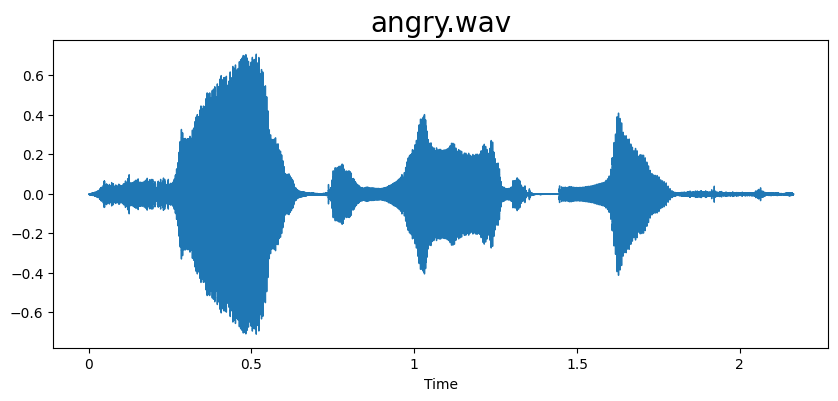

None

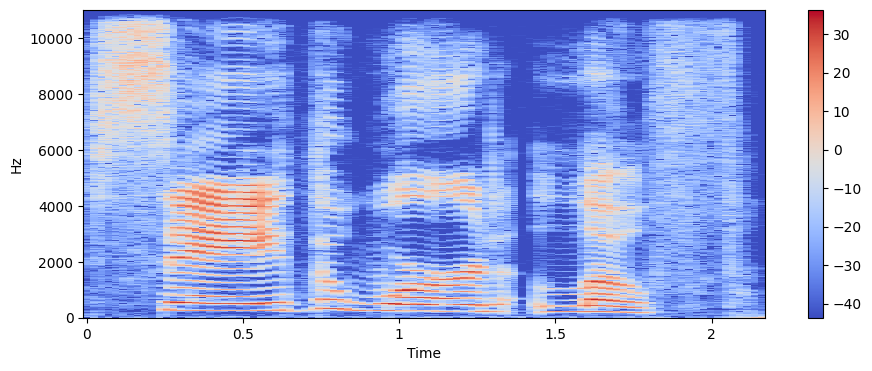

In [ ]:
for i in list(data['label'].unique()):
    display(ana_emotion(i, data))

In [ ]:
def MFCC(filename):
    y, sr = librosa.load(filename,duration=3,offset=0.5)
    return np.mean(librosa.feature.mfcc(y=y,sr=sr,n_mfcc=40).T,axis=0)

mfcc= data['speech'].apply(lambda x:MFCC(x))

In [ ]:
mfcc

0       [-551.9099, 117.02296, 44.473824, 18.151035, 1...
1       [-521.01794, 119.734406, 28.029362, 1.2564013,...
2       [-536.6411, 93.577324, 27.457087, 25.147121, 2...
3       [-516.2354, 93.02311, 24.75125, 3.9907653, 17....
4       [-528.4611, 105.532524, 33.695126, 19.274752, ...
                              ...                        
2745    [-440.78555, 80.94026, 10.855523, -6.173477, -...
2746    [-433.29758, 79.90519, 7.0025296, -17.684155, ...
2747    [-472.0142, 63.13129, 10.757127, 3.4197447, 10...
2748    [-428.7984, 82.43286, 5.2509885, -24.473654, 3...
2749    [-415.166, 70.506, 0.73379844, -23.595888, -12...
Name: speech, Length: 2750, dtype: object

In [ ]:
X=[x for x in mfcc]
X=np.array(X)
X.shape
X=np.expand_dims(X,-1)
X.shape

(2750, 40, 1)

In [ ]:
ohe=OneHotEncoder()
y = ohe.fit_transform( data[['label']] )
y= y.toarray()

In [ ]:
model=Sequential([
    LSTM(256,return_sequences=False,input_shape=(40,1)),
    Dense(128,activation='relu'),
    Dropout(0.2),
    Dense(64,activation='relu'),
    Dropout(0.2),
    Dense(7,activation='softmax')
])

model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 256)               264192    
                                                                 
 dense (Dense)               (None, 128)               32896     
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 7)                 455       
                                                                 
Total params: 305799 (1.17 MB)
Trainable params: 305799 

In [ ]:
#Train the model
history=model.fit(X,y,validation_split=0.2,epochs=50,batch_size=64)

Epoch 1/50


ValueError: in user code:

    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py", line 1401, in train_function  *
        return step_function(self, iterator)
    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py", line 1384, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py", line 1373, in run_step  **
        outputs = model.train_step(data)
    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py", line 1151, in train_step
        loss = self.compute_loss(x, y, y_pred, sample_weight)
    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py", line 1209, in compute_loss
        return self.compiled_loss(
    File "/usr/local/lib/python3.10/dist-packages/keras/src/engine/compile_utils.py", line 277, in __call__
        loss_value = loss_obj(y_t, y_p, sample_weight=sw)
    